In [34]:
from pathlib import Path
import time, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, roc_curve, auc)
from sklearn.base import clone
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA


In [2]:
try:
    from xgboost import XGBClassifier
    HAVE_XGBOOST = True
except ImportError:
    HAVE_XGBOOST = False
    print("XGBoost missing; install with %pip install xgboost and rerun this cell.")

RANDOM_STATE, TEST_SIZE = 42, 0.20
N_FEATURES, CORR_THRESHOLD = 22, 0.90
sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore", category=FutureWarning)

In [3]:
DATA_PATH = "cicddos2019_20k_balanced.csv"  # edit if needed
TARGET_COL = "Class"  # edit if needed

if not Path(DATA_PATH).exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}. Update DATA_PATH.")
df_raw = pd.read_csv(DATA_PATH)
df_raw.columns = [str(c).strip() for c in df_raw.columns]
print("Raw shape:", df_raw.shape)
print("Columns:", df_raw.columns.tolist())
display(df_raw.head())


Raw shape: (20000, 80)
Columns: ['Original_Index', 'Protocol', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Fwd Packets Length Total', 'Bwd Packets Length Total', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Packet Length Min', 'Packet Length Max', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'URG Flag Count

,Original_Index,Protocol,Flow Duration,Total Fwd Packets,Total Backward Packets,Fwd Packets Length Total,Bwd Packets Length Total,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,...,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,Class
0,214415,17,942,26,0,11008,0,440,224,423.3846,...,0.0,0.0,0,0,0.0,0.0,0,0,DrDoS_NTP,Attack
1,42560,6,199,1,2,0,0,0,0,0.0000,...,0.0,0.0,0,0,0.0,0.0,0,0,Benign,Benign
2,170762,17,20719,2,2,50,82,25,25,25.0000,...,0.0,0.0,0,0,0.0,0.0,0,0,Benign,Benign
3,106673,6,204,3,0,18,0,6,6,6.0000,...,0.0,0.0,0,0,0.0,0.0,0,0,Benign,Benign
4,176633,17,2033,76,0,33440,0,440,440,440.0000,...,0.0,0.0,0,0,0.0,0.0,0,0,DrDoS_NTP,Attack


In [4]:
import os
print(os.getcwd())

/Users/syedimran/Downloads/5771/projectv2


In [5]:
print(pd.__version__)


3.0.6


In [6]:

df = pd.read_csv(
    "/Users/syedimran/Downloads/5771/projectv2/cicddos2019_20k_balanced.csv"
)

print("Dataset shape:", df.shape)

Dataset shape: (20000, 80)


In [7]:
if TARGET_COL not in df_raw.columns:
    candidates = [c for c in df_raw.columns if c.lower() in {"class","label","target","attack"}]
    if len(candidates) == 1:
        TARGET_COL = candidates[0]
    else:
        raise ValueError(f"Set TARGET_COL manually. Available columns: {df_raw.columns.tolist()}")

print("Target counts before cleaning:")
display(df_raw[TARGET_COL].astype(str).str.strip().value_counts(dropna=False).to_frame("count"))
print("Duplicate rows:", int(df_raw.duplicated().sum()))
print("Missing values, top 15:")
display(df_raw.isna().sum().sort_values(ascending=False).head(15).to_frame("missing"))



Target counts before cleaning:


,count
Class,
Attack,10000
Benign,10000


Duplicate rows: 0
Missing values, top 15:


,missing
Original_Index,0
Protocol,0
Fwd Avg Bulk Rate,0
Fwd Avg Packets/Bulk,0
Fwd Avg Bytes/Bulk,0
Avg Bwd Segment Size,0
Avg Fwd Segment Size,0
Avg Packet Size,0
Down/Up Ratio,0
ECE Flag Count,0


In [8]:
df = df_raw.dropna(subset=[TARGET_COL]).copy()
df[TARGET_COL] = df[TARGET_COL].astype(str).str.strip()
df = df[df[TARGET_COL].ne("")]
df = df.replace([np.inf, -np.inf], np.nan).drop_duplicates().reset_index(drop=True)

target_text = df[TARGET_COL].str.lower()
benign_mask = target_text.str.contains("benign", regex=False)
if not benign_mask.any():
    raise ValueError("Could not identify benign target label; edit target mapping.")
y = (~benign_mask).astype(int)  # 0=Benign, 1=any non-benign attack

# Exclude obvious identifiers and duplicate label/attack-type fields. Review and edit this list.
exclude_patterns = [r"^id$", r"flow.?id", r"src.?ip", r"dst.?ip", r"source.?ip",
                    r"destination.?ip", r"timestamp", r"date.?time", r"attack.?type",
                    r"attack.?category", r"^label$", r"^target$", r"subcategory"]
excluded = [c for c in df.columns if c != TARGET_COL and
            any(re.search(p, c.lower()) for p in exclude_patterns)]
X = df.drop(columns=[TARGET_COL] + excluded, errors="ignore").copy()

# Keep numeric predictors (including numeric-looking strings); drop other categorical columns in this baseline.
for col in list(X.columns):
    if not pd.api.types.is_numeric_dtype(X[col]):
        conv = pd.to_numeric(X[col], errors="coerce")
        if conv.notna().mean() >= .90:
            X[col] = conv
        else:
            print("Dropping non-numeric predictor:", col)
            X.drop(columns=col, inplace=True)
X = X.dropna(axis=1, how="all").replace([np.inf, -np.inf], np.nan)
constant_cols = [c for c in X if X[c].nunique(dropna=True) <= 1]
X.drop(columns=constant_cols, inplace=True)

print("Cleaned rows:", len(X))
print("Excluded ID/leakage candidates:", excluded)
print("Constant columns removed:", constant_cols)
print("Eligible numeric feature count:", X.shape[1])
display(y.value_counts().rename(index={0:"Benign (0)",1:"DDoS/Attack (1)"}).to_frame("count"))



Cleaned rows: 20000
Excluded ID/leakage candidates: ['Label']
Constant columns removed: ['Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'FIN Flag Count', 'PSH Flag Count', 'ECE Flag Count', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']
Eligible numeric feature count: 66


,count
Class,
DDoS/Attack (1),10000
Benign (0),10000


In [9]:
print (X.head())

   Original_Index  Protocol  Flow Duration  Total Fwd Packets  \
0          214415        17            942                 26   
1           42560         6            199                  1   
2          170762        17          20719                  2   
3          106673         6            204                  3   
4          176633        17           2033                 76   

   Total Backward Packets  Fwd Packets Length Total  Bwd Packets Length Total  \
0                       0                     11008                         0   
1                       2                         0                         0   
2                       2                        50                        82   
3                       0                        18                         0   
4                       0                     33440                         0   

   Fwd Packet Length Max  Fwd Packet Length Min  Fwd Packet Length Mean  ...  \
0                    440                  

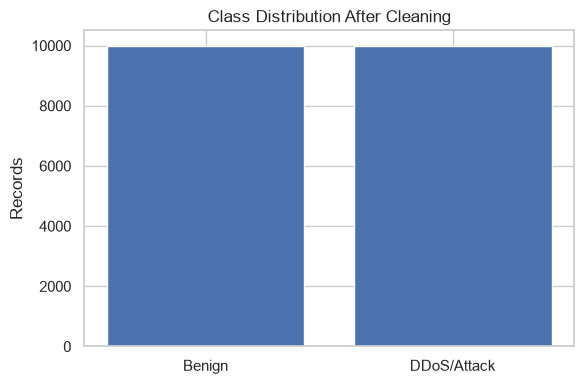

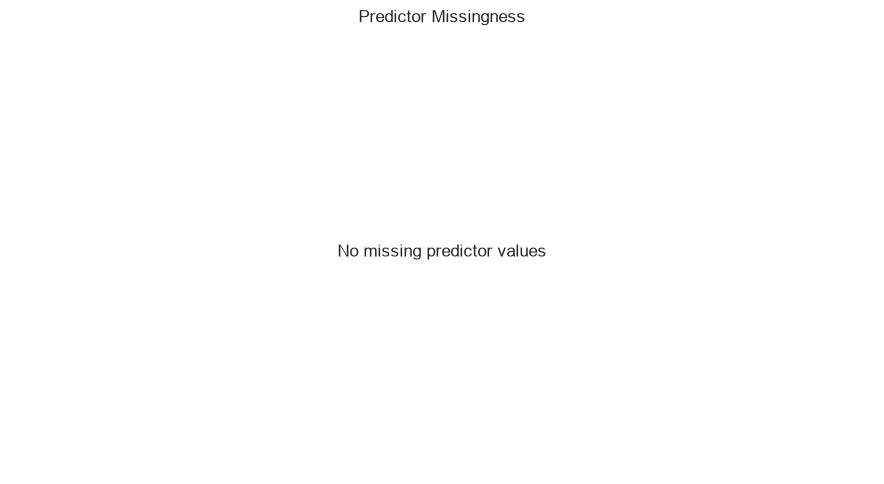

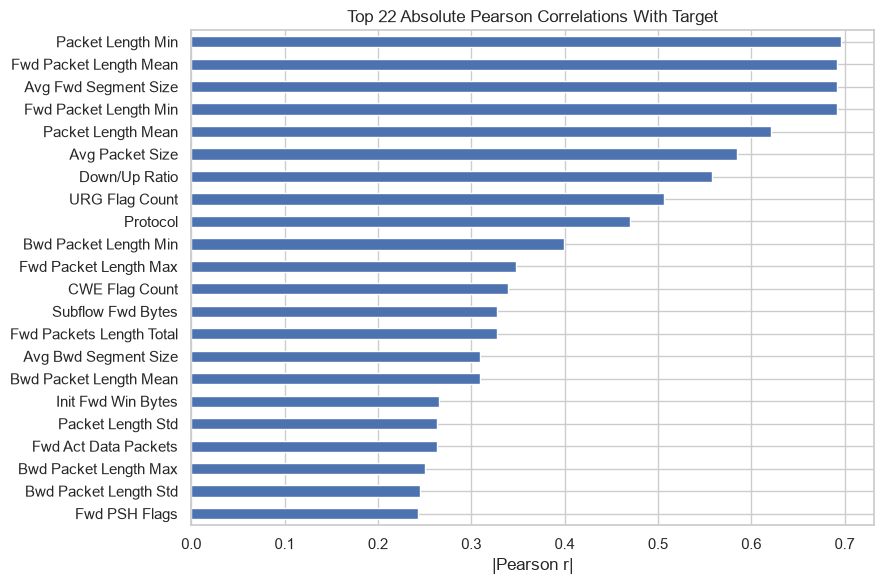

In [11]:
fig, ax = plt.subplots(figsize=(6,4))
counts = y.value_counts().sort_index()
ax.bar(["Benign", "DDoS/Attack"], [counts.get(0,0), counts.get(1,0)])
ax.set(title="Class Distribution After Cleaning", ylabel="Records")
plt.tight_layout(); plt.show()

missing_pct = (X.isna().mean()*100).sort_values(ascending=False)
missing_pct = missing_pct[missing_pct > 0].head(22)
fig, ax = plt.subplots(figsize=(9,5))
if len(missing_pct):
    missing_pct.sort_values().plot.barh(ax=ax)
    ax.set_xlabel("Missing values (%)")
else:
    ax.text(.5,.5,"No missing predictor values",ha="center",va="center")
    ax.set_axis_off()
ax.set_title("Predictor Missingness")
plt.tight_layout(); plt.show()

target_corr = X.corrwith(y).abs().sort_values(ascending=False).head(22)
fig, ax = plt.subplots(figsize=(9,6))
target_corr.sort_values().plot.barh(ax=ax)
ax.set(title="Top 22 Absolute Pearson Correlations With Target", xlabel="|Pearson r|")
plt.tight_layout(); plt.show()


In [12]:
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)
imputer = SimpleImputer(strategy="median")
X_train_imp = pd.DataFrame(imputer.fit_transform(X_train_raw), columns=X.columns, index=X_train_raw.index)
X_test_imp = pd.DataFrame(imputer.transform(X_test_raw), columns=X.columns, index=X_test_raw.index)
scaler = MinMaxScaler()
X_train_all = pd.DataFrame(scaler.fit_transform(X_train_imp), columns=X.columns, index=X_train_imp.index)
X_test_all = pd.DataFrame(scaler.transform(X_test_imp), columns=X.columns, index=X_test_imp.index)
print("Train/test:", X_train_all.shape, X_test_all.shape)


Train/test: (16000, 66) (4000, 66)


In [14]:
# ==========================================================
# K-MEANS CLUSTERING FOR EDA
# ==========================================================


# Use the ALL-FEATURE training data.
# The target variable is NOT used to create the clusters.
X_cluster = X_train_all.copy()

print("Data used for clustering:", X_cluster.shape)

# ----------------------------------------------------------
# 1. Run K-Means with 2 clusters
# ----------------------------------------------------------

kmeans = KMeans(
    n_clusters=2,
    random_state=RANDOM_STATE,
    n_init=10
)

cluster_labels = kmeans.fit_predict(X_cluster)

print("\nCluster sizes:")
print(pd.Series(cluster_labels).value_counts().sort_index())


Data used for clustering: (16000, 66)

Cluster sizes:
0    12667
1     3333
Name: count, dtype: int64


In [15]:

# ----------------------------------------------------------
# 2. PCA for visualization (Cluusturing)
# ----------------------------------------------------------

pca = PCA(n_components=2, random_state=RANDOM_STATE)

X_pca = pca.fit_transform(X_cluster)

explained_variance = pca.explained_variance_ratio_

print("\nPCA explained variance:")
print(f"PC1: {explained_variance[0]:.4f}")
print(f"PC2: {explained_variance[1]:.4f}")
print(f"Total: {explained_variance.sum():.4f}")





PCA explained variance:
PC1: 0.2986
PC2: 0.2548
Total: 0.5534


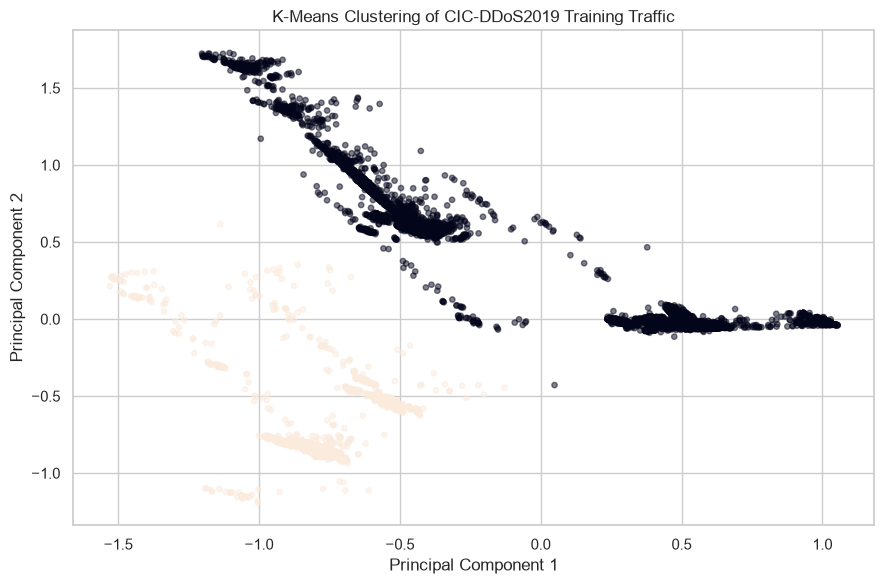

In [16]:
# ----------------------------------------------------------
# 3. Plot K-Means clusters
# ----------------------------------------------------------

plt.figure(figsize=(9, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=cluster_labels,
    alpha=0.5,
    s=15
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clustering of CIC-DDoS2019 Training Traffic")

plt.tight_layout()
plt.show()


In [17]:

# ----------------------------------------------------------
# 4. Compare clusters with the actual labels
#    NOTE: y_train is NOT used to create the clusters.
#    It is only used here to interpret the clusters.
# ----------------------------------------------------------

cluster_comparison = pd.crosstab(
    cluster_labels,
    y_train
)

cluster_comparison.columns = ["Benign", "DDoS/Attack"]

print("\nCluster vs. Actual Class:")
display(cluster_comparison)



Cluster vs. Actual Class:


,Benign,DDoS/Attack
row_0,,
0,4678,7989
1,3322,11


In [18]:
# ----------------------------------------------------------
# 5. Show percentage of each class within each cluster
# ----------------------------------------------------------

cluster_percentage = pd.crosstab(
    cluster_labels,
    y_train,
    normalize="index"
) * 100

cluster_percentage.columns = ["Benign (%)", "DDoS/Attack (%)"]

print("\nClass composition within each cluster:")
display(cluster_percentage)


Class composition within each cluster:


,Benign (%),DDoS/Attack (%)
row_0,,
0,36.930607,63.069393
1,99.669967,0.330033


In [19]:

# ==========================================
# PEARSON CORRELATION FEATURE SELECTION
# ==========================================

N_FEATURES = 22
CORR_THRESHOLD = 0.90

# Step 1: Calculate each feature's correlation with the target
target_corr = X_train_all.corrwith(
    pd.Series(y_train, index=X_train_all.index)
).abs()

# Step 2: Rank features by absolute target correlation
ranked_features = (
    target_corr
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
    .sort_values(ascending=False)
    .index.tolist()
)

# Step 3: Select features while avoiding highly correlated predictors
selected_features = []

for feature in ranked_features:
    is_redundant = any(
        abs(X_train_all[feature].corr(X_train_all[selected]))
        > CORR_THRESHOLD
        for selected in selected_features
    )

    if not is_redundant:
        selected_features.append(feature)

    if len(selected_features) == N_FEATURES:
        break

# Step 4: If needed, fill remaining slots with the next highest-ranked features
if len(selected_features) < N_FEATURES:
    for feature in ranked_features:
        if feature not in selected_features:
            selected_features.append(feature)

        if len(selected_features) == N_FEATURES:
            break

if len(selected_features) != N_FEATURES:
    raise ValueError(
        f"Only {len(selected_features)} usable features available."
    )

# Step 5: Display the selected features and their correlations with target
feature_summary = pd.DataFrame({
    "Feature": selected_features,
    "Pearson Correlation with Target": [
        X_train_all[f].corr(pd.Series(y_train, index=X_train_all.index))
        for f in selected_features
    ]
})

display(feature_summary)

print("Number of selected features:", len(selected_features))

# Step 6: Create the 22-feature training and testing datasets
X_train_22 = X_train_all[selected_features].copy()
X_test_22 = X_test_all[selected_features].copy()

print("Training shape:", X_train_22.shape)
print("Testing shape:", X_test_22.shape)


,Feature,Pearson Correlation with Target
0,Packet Length Min,0.697478
1,Packet Length Mean,0.623357
2,Down/Up Ratio,-0.558159
3,URG Flag Count,-0.509668
4,Protocol,0.478299
5,Bwd Packet Length Min,-0.406591
6,Fwd Packet Length Max,0.350979
7,CWE Flag Count,-0.343416
8,Subflow Fwd Bytes,0.329502
9,Avg Bwd Segment Size,-0.310149


Number of selected features: 22
Training shape: (16000, 22)
Testing shape: (4000, 22)


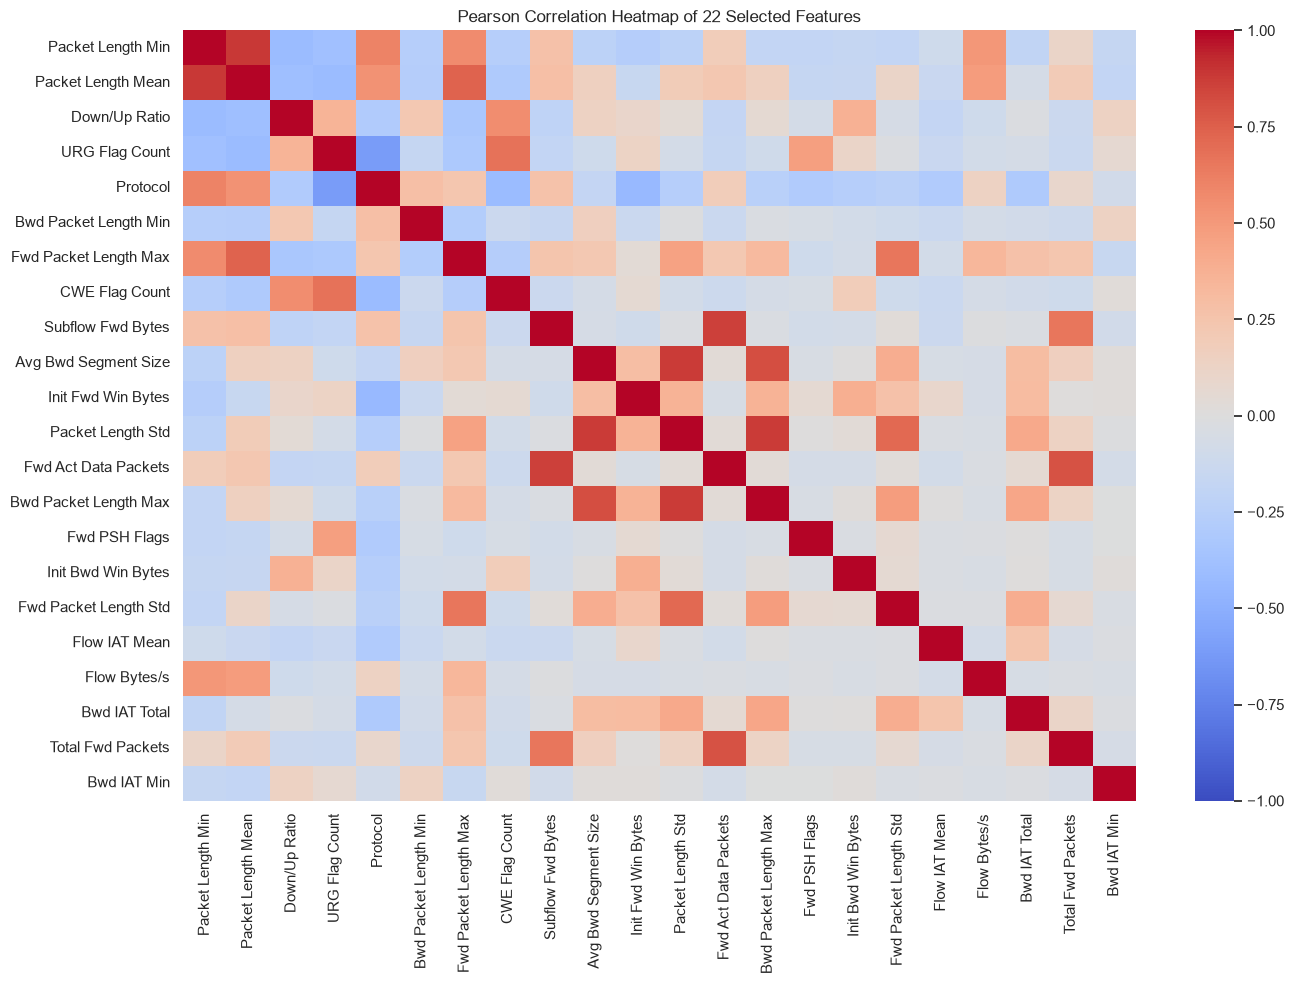

In [20]:

plt.figure(figsize=(14, 10))

sns.heatmap(
    X_train_all[selected_features].corr(),
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    annot=False
)

plt.title("Pearson Correlation Heatmap of 22 Selected Features")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


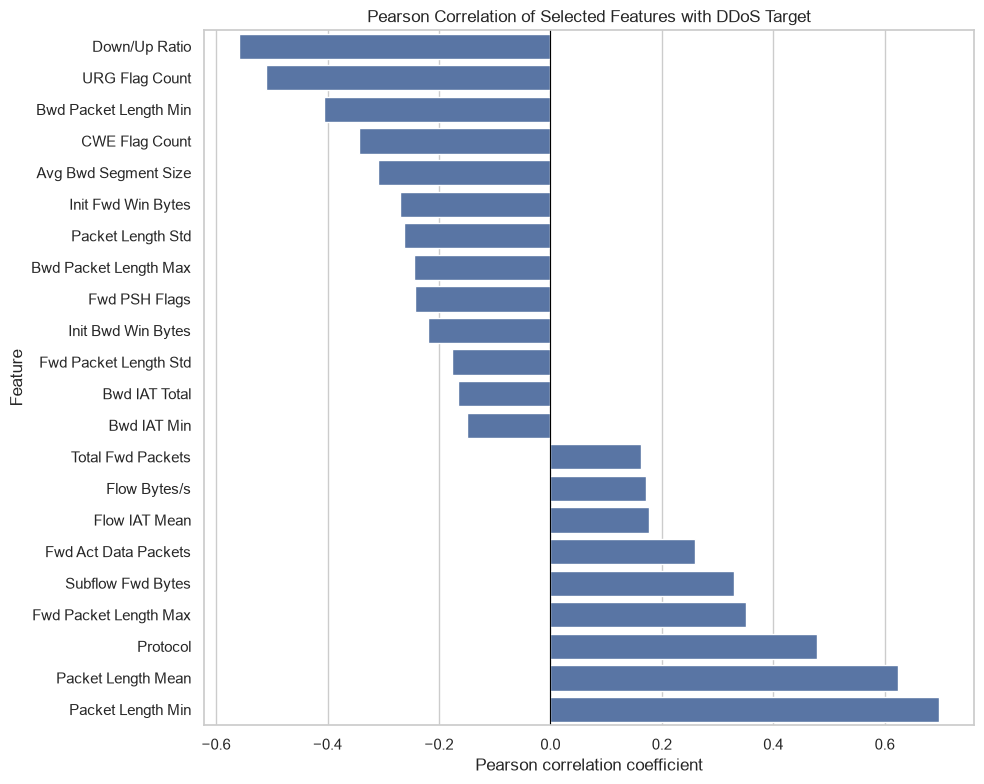

In [21]:
#how strongly each selected feature correlates with the target
feature_summary_sorted = feature_summary.sort_values(
    "Pearson Correlation with Target"
)

plt.figure(figsize=(10, 8))

sns.barplot(
    data=feature_summary_sorted,
    x="Pearson Correlation with Target",
    y="Feature"
)

plt.axvline(0, color="black", linewidth=0.8)
plt.title("Pearson Correlation of Selected Features with DDoS Target")
plt.xlabel("Pearson correlation coefficient")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()



In [22]:
models = {
 "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE, class_weight="balanced"),
 "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1, class_weight="balanced"),
 "AdaBoost": AdaBoostClassifier(n_estimators=100, learning_rate=.5, random_state=RANDOM_STATE),
 "MLP": MLPClassifier(hidden_layer_sizes=(64,), max_iter=250, early_stopping=True, random_state=RANDOM_STATE),
 "DNN": MLPClassifier(hidden_layer_sizes=(128,64,32), max_iter=300, early_stopping=True, random_state=RANDOM_STATE)
}
if HAVE_XGBOOST:
    models["XGBoost"] = XGBClassifier(n_estimators=200, max_depth=6, learning_rate=.1,
        subsample=.9, colsample_bytree=.9, objective="binary:logistic",
        eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1)
print("Models included:", list(models))


Models included: ['Decision Tree', 'Random Forest', 'AdaBoost', 'MLP', 'DNN', 'XGBoost']


In [24]:
def get_scores(model, data):
    if hasattr(model, "predict_proba"):
        p = model.predict_proba(data)
        return p[:,1] if p.ndim == 2 and p.shape[1] > 1 else None
    if hasattr(model, "decision_function"):
        return model.decision_function(data)
    return None

def run_experiment(Xtr, Xte, name):
    rows, fitted, pred_info = [], {}, {}
    for model_name, estimator in models.items():
        model = clone(estimator)
        t0 = time.perf_counter(); model.fit(Xtr, y_train); train_s = time.perf_counter()-t0
        t0 = time.perf_counter(); pred = model.predict(Xte); pred_s = time.perf_counter()-t0
        scores = get_scores(model, Xte)
        try:
            auc_score = roc_auc_score(y_test, scores) if scores is not None else np.nan
        except ValueError:
            auc_score = np.nan
        rows.append({"Feature Set":name, "Model":model_name, "Features":Xtr.shape[1],
            "Accuracy":accuracy_score(y_test,pred),
            "Precision":precision_score(y_test,pred,zero_division=0),
            "Recall":recall_score(y_test,pred,zero_division=0),
            "F1":f1_score(y_test,pred,zero_division=0),
            "ROC-AUC":auc_score, "Training Time (s)":train_s,
            "Prediction Time (s)":pred_s,
            "Prediction (ms/record)":1000*pred_s/len(Xte)})
        fitted[(name,model_name)] = model
        pred_info[(name,model_name)] = {"pred":pred, "scores":scores}
        print(f"{name:12s} | {model_name:15s} | F1={rows[-1]['F1']:.4f}")
    return pd.DataFrame(rows), fitted, pred_info

res_all, fit_all, pred_all = run_experiment(X_train_all, X_test_all, "All features")
res_22, fit_22, pred_22 = run_experiment(X_train_22, X_test_22, "Pearson 22")
results = pd.concat([res_all,res_22],ignore_index=True)
display(results.sort_values(["Model","Feature Set"]).round(4))


All features | Decision Tree   | F1=0.9982
All features | Random Forest   | F1=0.9982
All features | AdaBoost        | F1=0.9965
All features | MLP             | F1=0.9965
All features | DNN             | F1=0.9967
All features | XGBoost         | F1=0.9992
Pearson 22   | Decision Tree   | F1=0.9975
Pearson 22   | Random Forest   | F1=0.9980
Pearson 22   | AdaBoost        | F1=0.9955
Pearson 22   | MLP             | F1=0.9903
Pearson 22   | DNN             | F1=0.9965
Pearson 22   | XGBoost         | F1=0.9992


,Feature Set,Model,Features,Accuracy,Precision,Recall,F1,ROC-AUC,Training Time (s),Prediction Time (s),Prediction (ms/record)
2,All features,AdaBoost,66,0.9965,0.9965,0.9965,0.9965,0.9996,4.0505,0.0391,0.0098
8,Pearson 22,AdaBoost,22,0.9955,0.9955,0.9955,0.9955,0.9992,1.2919,0.0235,0.0059
4,All features,DNN,66,0.9968,0.9975,0.9960,0.9967,0.9976,0.8204,0.0033,0.0008
10,Pearson 22,DNN,22,0.9965,0.9980,0.9950,0.9965,0.9993,1.4846,0.0029,0.0007
0,All features,Decision Tree,66,0.9982,0.9990,0.9975,0.9982,0.9982,0.2432,0.0025,0.0006
6,Pearson 22,Decision Tree,22,0.9975,0.9985,0.9965,0.9975,0.9975,0.0450,0.0010,0.0002
3,All features,MLP,66,0.9965,0.9985,0.9945,0.9965,0.9983,1.3549,0.0022,0.0005
9,Pearson 22,MLP,22,0.9902,0.9852,0.9955,0.9903,0.9970,0.5958,0.0013,0.0003
1,All features,Random Forest,66,0.9982,1.0000,0.9965,0.9982,1.0000,0.8293,0.0425,0.0106
7,Pearson 22,Random Forest,22,0.9980,0.9990,0.9970,0.9980,1.0000,0.5219,0.0670,0.0168


In [35]:
# ==========================================================
# STRATIFIED 5-FOLD CROSS-VALIDATION
# ==========================================================

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

print("Stratified 5-Fold Cross-Validation")
print("----------------------------------")


def select_pearson_features(X_train_fold, y_train_fold,
                            n_features=22, corr_threshold=0.90):
    """
    Select Pearson-correlated features using ONLY the training
    portion of the current CV fold.
    """

    # Correlation between each predictor and target
    target_corr = X_train_fold.corrwith(
        pd.Series(y_train_fold, index=X_train_fold.index)
    ).abs()

    ranked_features = (
        target_corr
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
        .sort_values(ascending=False)
        .index.tolist()
    )

    selected = []

    # Avoid highly correlated/redundant predictors
    for feature in ranked_features:

        is_redundant = any(
            abs(
                X_train_fold[feature].corr(
                    X_train_fold[selected_feature]
                )
            ) > corr_threshold
            for selected_feature in selected
        )

        if not is_redundant:
            selected.append(feature)

        if len(selected) == n_features:
            break

    # Fill remaining slots if necessary
    if len(selected) < n_features:

        for feature in ranked_features:

            if feature not in selected:
                selected.append(feature)

            if len(selected) == n_features:
                break

    if len(selected) != n_features:
        raise ValueError(
            f"Could only select {len(selected)} features."
        )

    return selected


def run_stratified_cv(X_raw, y_data, feature_set_name):
    """
    Run leakage-safe Stratified 5-Fold CV.

    Preprocessing and Pearson feature selection are performed
    independently inside every fold.
    """

    cv_rows = []

    print(f"\nFeature Set: {feature_set_name}")
    print("=" * 60)

    for model_name, estimator in models.items():

        fold_results = []

        for fold, (train_idx, val_idx) in enumerate(
            cv.split(X_raw, y_data), start=1
        ):

            # --------------------------------------------------
            # Split current fold
            # --------------------------------------------------

            X_fold_train = X_raw.iloc[train_idx].copy()
            X_fold_val = X_raw.iloc[val_idx].copy()

            y_fold_train = y_data.iloc[train_idx]
            y_fold_val = y_data.iloc[val_idx]

            # --------------------------------------------------
            # Imputation - FIT ONLY ON FOLD TRAINING DATA
            # --------------------------------------------------

            fold_imputer = SimpleImputer(strategy="median")

            X_fold_train_imp = pd.DataFrame(
                fold_imputer.fit_transform(X_fold_train),
                columns=X_raw.columns,
                index=X_fold_train.index
            )

            X_fold_val_imp = pd.DataFrame(
                fold_imputer.transform(X_fold_val),
                columns=X_raw.columns,
                index=X_fold_val.index
            )

            # --------------------------------------------------
            # Scaling - FIT ONLY ON FOLD TRAINING DATA
            # --------------------------------------------------

            fold_scaler = MinMaxScaler()

            X_fold_train_scaled = pd.DataFrame(
                fold_scaler.fit_transform(X_fold_train_imp),
                columns=X_raw.columns,
                index=X_fold_train.index
            )

            X_fold_val_scaled = pd.DataFrame(
                fold_scaler.transform(X_fold_val_imp),
                columns=X_raw.columns,
                index=X_fold_val.index
            )

            # --------------------------------------------------
            # Feature selection
            # --------------------------------------------------

            if feature_set_name == "All features":

                X_fold_train_final = X_fold_train_scaled
                X_fold_val_final = X_fold_val_scaled

            elif feature_set_name == "Pearson 22":

                # IMPORTANT:
                # Pearson selection happens ONLY using
                # the training portion of this fold.

                fold_features = select_pearson_features(
                    X_fold_train_scaled,
                    y_fold_train,
                    n_features=22,
                    corr_threshold=0.90
                )

                X_fold_train_final = (
                    X_fold_train_scaled[fold_features]
                )

                X_fold_val_final = (
                    X_fold_val_scaled[fold_features]
                )

            else:
                raise ValueError(
                    f"Unknown feature set: {feature_set_name}"
                )

            # --------------------------------------------------
            # Train model
            # --------------------------------------------------

            model = clone(estimator)

            start_time = time.perf_counter()

            model.fit(
                X_fold_train_final,
                y_fold_train
            )

            train_time = (
                time.perf_counter() - start_time
            )

            # --------------------------------------------------
            # Validation prediction
            # --------------------------------------------------

            start_time = time.perf_counter()

            predictions = model.predict(
                X_fold_val_final
            )

            prediction_time = (
                time.perf_counter() - start_time
            )

            # --------------------------------------------------
            # Probability / decision scores
            # --------------------------------------------------

            scores = get_scores(
                model,
                X_fold_val_final
            )

            if scores is not None:

                auc_score = roc_auc_score(
                    y_fold_val,
                    scores
                )

            else:
                auc_score = np.nan

            # --------------------------------------------------
            # Store fold results
            # --------------------------------------------------

            fold_results.append({
                "Fold": fold,
                "Accuracy": accuracy_score(
                    y_fold_val,
                    predictions
                ),
                "Precision": precision_score(
                    y_fold_val,
                    predictions,
                    zero_division=0
                ),
                "Recall": recall_score(
                    y_fold_val,
                    predictions,
                    zero_division=0
                ),
                "F1": f1_score(
                    y_fold_val,
                    predictions,
                    zero_division=0
                ),
                "ROC-AUC": auc_score,
                "Training Time (s)": train_time,
                "Prediction Time (s)": prediction_time
            })

        # ------------------------------------------------------
        # Calculate mean and standard deviation across 5 folds
        # ------------------------------------------------------

        fold_df = pd.DataFrame(fold_results)

        cv_rows.append({
            "Feature Set": feature_set_name,
            "Model": model_name,

            "CV Accuracy Mean":
                fold_df["Accuracy"].mean(),

            "CV Accuracy Std":
                fold_df["Accuracy"].std(),

            "CV Precision Mean":
                fold_df["Precision"].mean(),

            "CV Precision Std":
                fold_df["Precision"].std(),

            "CV Recall Mean":
                fold_df["Recall"].mean(),

            "CV Recall Std":
                fold_df["Recall"].std(),

            "CV F1 Mean":
                fold_df["F1"].mean(),

            "CV F1 Std":
                fold_df["F1"].std(),

            "CV ROC-AUC Mean":
                fold_df["ROC-AUC"].mean(),

            "CV ROC-AUC Std":
                fold_df["ROC-AUC"].std(),

            "CV Training Time Mean (s)":
                fold_df["Training Time (s)"].mean(),

            "CV Prediction Time Mean (s)":
                fold_df["Prediction Time (s)"].mean()
        })

        print(
            f"{feature_set_name:12s} | "
            f"{model_name:15s} | "
            f"F1 = {fold_df['F1'].mean():.4f} "
            f"(± {fold_df['F1'].std():.4f})"
        )

    return pd.DataFrame(cv_rows)

Stratified 5-Fold Cross-Validation
----------------------------------


In [36]:
# ==========================================================
# RUN STRATIFIED 5-FOLD CV
# ==========================================================

cv_all = run_stratified_cv(
    X_train_raw,
    y_train,
    "All features"
)

cv_22 = run_stratified_cv(
    X_train_raw,
    y_train,
    "Pearson 22"
)

cv_results = pd.concat(
    [cv_all, cv_22],
    ignore_index=True
)

print("\nFinal Cross-Validation Results:")
display(
    cv_results.round(4)
)


Feature Set: All features
All features | Decision Tree   | F1 = 0.9981 (± 0.0012)
All features | Random Forest   | F1 = 0.9986 (± 0.0005)
All features | AdaBoost        | F1 = 0.9971 (± 0.0008)
All features | MLP             | F1 = 0.9949 (± 0.0022)
All features | DNN             | F1 = 0.9972 (± 0.0013)
All features | XGBoost         | F1 = 0.9988 (± 0.0006)

Feature Set: Pearson 22
Pearson 22   | Decision Tree   | F1 = 0.9978 (± 0.0012)
Pearson 22   | Random Forest   | F1 = 0.9984 (± 0.0009)
Pearson 22   | AdaBoost        | F1 = 0.9957 (± 0.0010)
Pearson 22   | MLP             | F1 = 0.9918 (± 0.0006)
Pearson 22   | DNN             | F1 = 0.9954 (± 0.0031)
Pearson 22   | XGBoost         | F1 = 0.9984 (± 0.0008)

Final Cross-Validation Results:


,Feature Set,Model,CV Accuracy Mean,CV Accuracy Std,CV Precision Mean,CV Precision Std,CV Recall Mean,CV Recall Std,CV F1 Mean,CV F1 Std,CV ROC-AUC Mean,CV ROC-AUC Std,CV Training Time Mean (s),CV Prediction Time Mean (s)
0,All features,Decision Tree,0.9981,0.0012,0.9985,0.0011,0.9976,0.0016,0.9981,0.0012,0.9981,0.0012,0.1639,0.0013
1,All features,Random Forest,0.9986,0.0005,0.9997,0.0003,0.9974,0.0009,0.9986,0.0005,0.9999,0.0002,0.6873,0.0436
2,All features,AdaBoost,0.9971,0.0008,0.9972,0.0010,0.9969,0.0013,0.9971,0.0008,0.9996,0.0004,3.1083,0.0272
3,All features,MLP,0.9949,0.0022,0.9939,0.0035,0.9959,0.0019,0.9949,0.0022,0.9985,0.0011,0.5421,0.0017
4,All features,DNN,0.9972,0.0013,0.9984,0.0013,0.9961,0.0032,0.9972,0.0013,0.9993,0.0004,0.8795,0.0032
5,All features,XGBoost,0.9988,0.0006,0.9999,0.0003,0.9978,0.0012,0.9988,0.0006,0.9999,0.0002,0.6590,0.0064
6,Pearson 22,Decision Tree,0.9978,0.0012,0.9978,0.0020,0.9978,0.0010,0.9978,0.0012,0.9977,0.0012,0.0420,0.0009
7,Pearson 22,Random Forest,0.9984,0.0009,0.9992,0.0008,0.9975,0.0014,0.9984,0.0009,0.9998,0.0002,0.4855,0.0572
8,Pearson 22,AdaBoost,0.9957,0.0010,0.9951,0.0015,0.9962,0.0021,0.9957,0.0010,0.9993,0.0003,1.0659,0.0204
9,Pearson 22,MLP,0.9918,0.0006,0.9872,0.0013,0.9964,0.0010,0.9918,0.0006,0.9980,0.0006,0.6746,0.0013


In [40]:
# ==========================================================
# ADD CV RESULTS TO EXPERIMENT RESULTS
# ==========================================================

experiment_log = results.merge(
    cv_results,
    on=["Feature Set", "Model"],
    how="left"
)

experiment_log["Run"] = range(
    1,
    len(experiment_log) + 1
)

experiment_log["Random State"] = RANDOM_STATE
experiment_log["Test Size"] = TEST_SIZE
experiment_log["CV Folds"] = 5

experiment_log["Feature Selection"] = (
    experiment_log["Feature Set"].map({
        "All features":
            "All eligible features",

        "Pearson 22":
            "Top 22 features selected by absolute Pearson correlation"
    })
)

experiment_log["Notes"] = (
    experiment_log["Feature Set"].map({
        "All features":
            "Baseline using all eligible features",

        "Pearson 22":
            "Feature-reduction experiment"
    })
)

display(
    experiment_log.round(4)
)

,Feature Set,Model,Features,Accuracy,Precision,Recall,F1,ROC-AUC,Training Time (s),Prediction Time (s),...,CV ROC-AUC Mean,CV ROC-AUC Std,CV Training Time Mean (s),CV Prediction Time Mean (s),Run,Random State,Test Size,CV Folds,Feature Selection,Notes
0,All features,Decision Tree,66,0.9982,0.9990,0.9975,0.9982,0.9982,0.2432,0.0025,...,0.9981,0.0012,0.1639,0.0013,1,42,0.2,5,All eligible features,Baseline using all eligible features
1,All features,Random Forest,66,0.9982,1.0000,0.9965,0.9982,1.0000,0.8293,0.0425,...,0.9999,0.0002,0.6873,0.0436,2,42,0.2,5,All eligible features,Baseline using all eligible features
2,All features,AdaBoost,66,0.9965,0.9965,0.9965,0.9965,0.9996,4.0505,0.0391,...,0.9996,0.0004,3.1083,0.0272,3,42,0.2,5,All eligible features,Baseline using all eligible features
3,All features,MLP,66,0.9965,0.9985,0.9945,0.9965,0.9983,1.3549,0.0022,...,0.9985,0.0011,0.5421,0.0017,4,42,0.2,5,All eligible features,Baseline using all eligible features
4,All features,DNN,66,0.9968,0.9975,0.9960,0.9967,0.9976,0.8204,0.0033,...,0.9993,0.0004,0.8795,0.0032,5,42,0.2,5,All eligible features,Baseline using all eligible features
5,All features,XGBoost,66,0.9992,1.0000,0.9985,0.9992,0.9999,0.5898,0.0065,...,0.9999,0.0002,0.6590,0.0064,6,42,0.2,5,All eligible features,Baseline using all eligible features
6,Pearson 22,Decision Tree,22,0.9975,0.9985,0.9965,0.9975,0.9975,0.0450,0.0010,...,0.9977,0.0012,0.0420,0.0009,7,42,0.2,5,Top 22 features selected by absolute Pearson c...,Feature-reduction experiment
7,Pearson 22,Random Forest,22,0.9980,0.9990,0.9970,0.9980,1.0000,0.5219,0.0670,...,0.9998,0.0002,0.4855,0.0572,8,42,0.2,5,Top 22 features selected by absolute Pearson c...,Feature-reduction experiment
8,Pearson 22,AdaBoost,22,0.9955,0.9955,0.9955,0.9955,0.9992,1.2919,0.0235,...,0.9993,0.0003,1.0659,0.0204,9,42,0.2,5,Top 22 features selected by absolute Pearson c...,Feature-reduction experiment
9,Pearson 22,MLP,22,0.9902,0.9852,0.9955,0.9903,0.9970,0.5958,0.0013,...,0.9980,0.0006,0.6746,0.0013,10,42,0.2,5,Top 22 features selected by absolute Pearson c...,Feature-reduction experiment


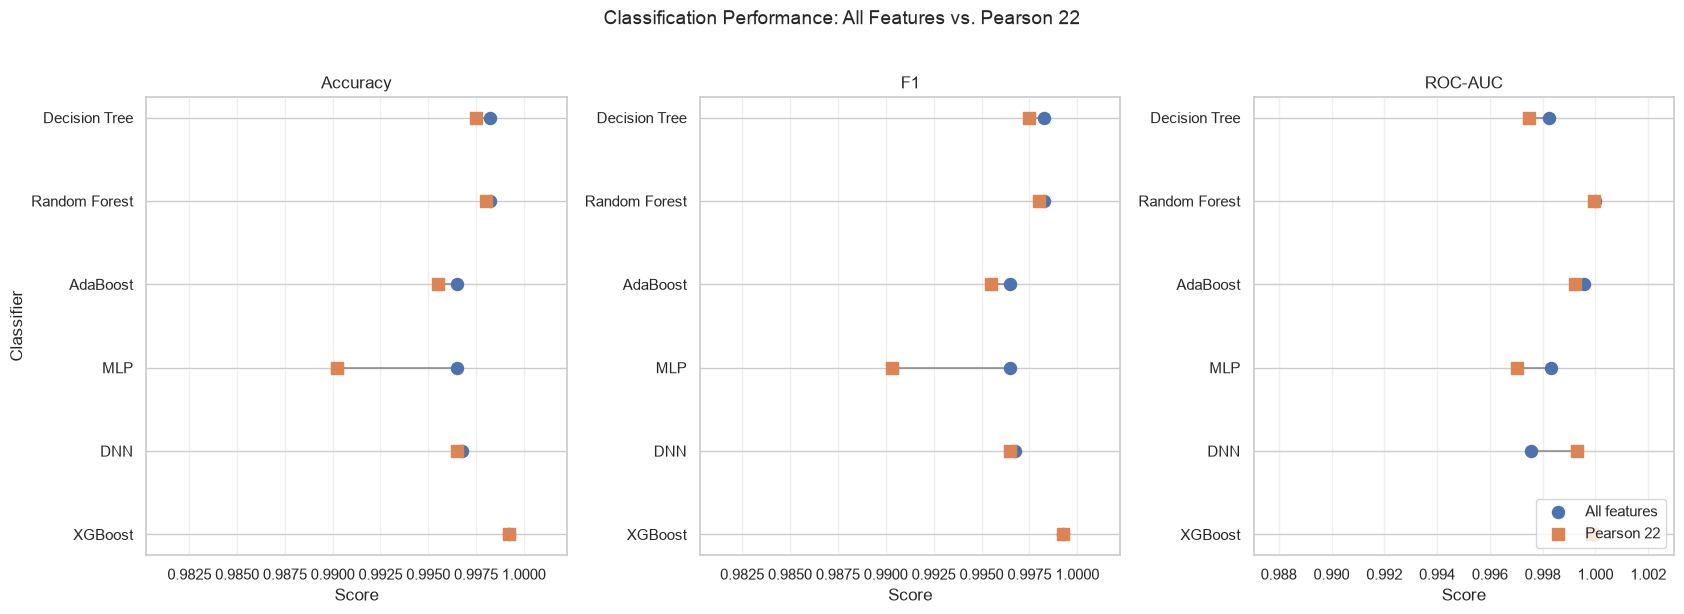

In [41]:
sns.set_theme(style="whitegrid", context="notebook")

metrics = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]

# Prepare paired results
all_results = (
    results[results["Feature Set"] == "All features"]
    .set_index("Model")
)
pearson_results = (
    results[results["Feature Set"] == "Pearson 22"]
    .set_index("Model")
)

model_order = all_results.index.tolist()

# --------------------------------------------------
# FIGURE 1: Performance comparison using paired dots
# --------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(17, 6))

for ax, metric in zip(axes, ["Accuracy", "F1", "ROC-AUC"]):
    all_scores = all_results.loc[model_order, metric]
    pearson_scores = pearson_results.loc[model_order, metric]
    positions = np.arange(len(model_order))

    # Connect the two scores for each model
    for i in range(len(model_order)):
        ax.plot(
            [all_scores.iloc[i], pearson_scores.iloc[i]],
            [positions[i], positions[i]],
            color="gray", alpha=0.7, linewidth=1.5
        )

    ax.scatter(all_scores, positions, marker="o", s=75,
               label="All features", zorder=3)
    ax.scatter(pearson_scores, positions, marker="s", s=75,
               label="Pearson 22", zorder=3)

    ax.set_yticks(positions)
    ax.set_yticklabels(model_order)
    ax.invert_yaxis()
    ax.set_title(metric)
    ax.set_xlabel("Score")

    # Zoom in only when differences are small and scores are high
    combined = pd.concat([all_scores, pearson_scores]).dropna()
    if len(combined) and combined.min() >= 0.90:
        ax.set_xlim(
            max(0, combined.min() - 0.01),
            min(1.005, combined.max() + 0.003)
        )

    ax.grid(axis="x", alpha=0.3)

axes[0].set_ylabel("Classifier")
axes[-1].legend(loc="lower right")
fig.suptitle(
    "Classification Performance: All Features vs. Pearson 22",
    fontsize=14, y=1.02
)
plt.tight_layout()
plt.show()









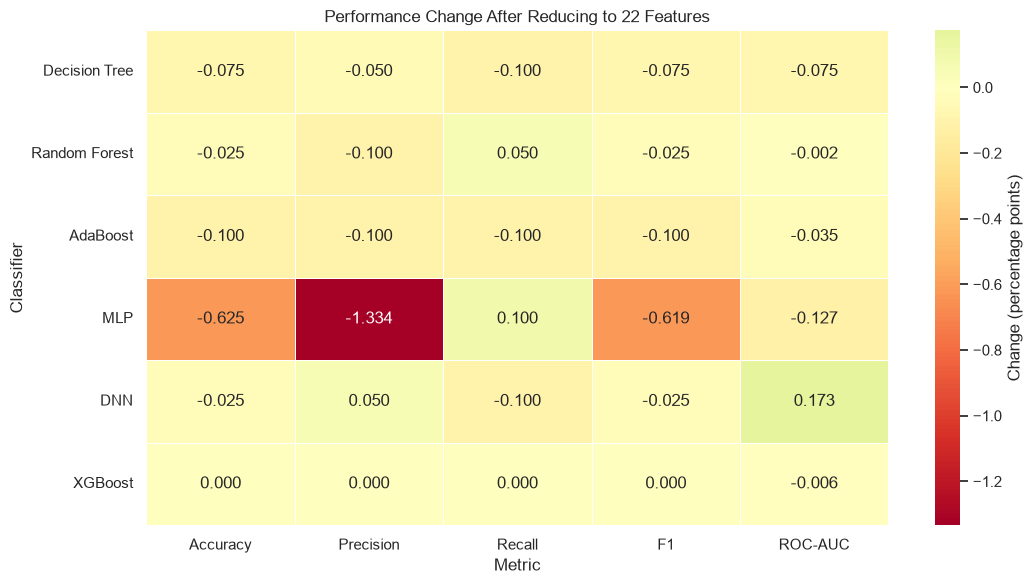

In [42]:
# --------------------------------------------------
# FIGURE 2: Performance changes in percentage points
# --------------------------------------------------
delta = pd.DataFrame(index=model_order)

for metric in metrics:
    delta[metric] = (
        pearson_results.loc[model_order, metric]
        - all_results.loc[model_order, metric]
    ) * 100

plt.figure(figsize=(11, 6))
sns.heatmap(
    delta,
    annot=True,
    fmt=".3f",
    center=0,
    cmap="RdYlGn",
    linewidths=0.5,
    cbar_kws={"label": "Change (percentage points)"}
)
plt.title("Performance Change After Reducing to 22 Features")
plt.xlabel("Metric")
plt.ylabel("Classifier")
plt.tight_layout()
plt.show()


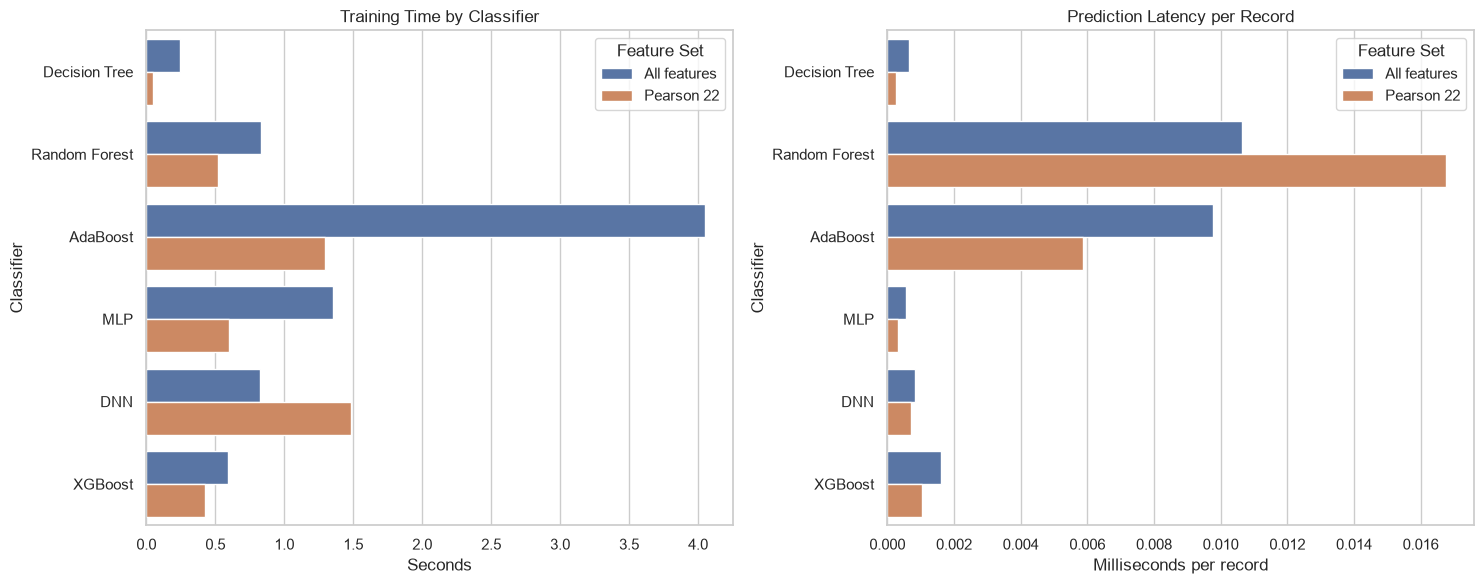

In [43]:
# --------------------------------------------------
# FIGURE 3: Training time and prediction latency
# --------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.barplot(
    data=results,
    x="Training Time (s)",
    y="Model",
    hue="Feature Set",
    order=model_order,
    ax=axes[0]
)
axes[0].set_title("Training Time by Classifier")
axes[0].set_xlabel("Seconds")
axes[0].set_ylabel("Classifier")

sns.barplot(
    data=results,
    x="Prediction (ms/record)",
    y="Model",
    hue="Feature Set",
    order=model_order,
    ax=axes[1]
)
axes[1].set_title("Prediction Latency per Record")
axes[1].set_xlabel("Milliseconds per record")
axes[1].set_ylabel("Classifier")

plt.tight_layout()
plt.show()






In [44]:
# --------------------------------------------------
# TABLE: Exact scores and changes
# --------------------------------------------------
comparison = pd.DataFrame(index=model_order)

for metric in metrics:
    comparison[f"{metric} (all)"] = all_results.loc[model_order, metric]
    comparison[f"{metric} (22)"] = pearson_results.loc[model_order, metric]
    comparison[f"{metric} change (pp)"] = (
        pearson_results.loc[model_order, metric]
        - all_results.loc[model_order, metric]
    ) * 100

display(comparison.round(5))

,Accuracy (all),Accuracy (22),Accuracy change (pp),Precision (all),Precision (22),Precision change (pp),Recall (all),Recall (22),Recall change (pp),F1 (all),F1 (22),F1 change (pp),ROC-AUC (all),ROC-AUC (22),ROC-AUC change (pp)
Decision Tree,0.99825,0.99750,-0.075,0.99900,0.99850,-0.05015,0.9975,0.9965,-0.10,0.99825,0.99750,-0.07512,0.99825,0.99750,-0.07500
Random Forest,0.99825,0.99800,-0.025,1.00000,0.99900,-0.10020,0.9965,0.9970,0.05,0.99825,0.99800,-0.02489,0.99998,0.99996,-0.00211
AdaBoost,0.99650,0.99550,-0.100,0.99650,0.99550,-0.10000,0.9965,0.9955,-0.10,0.99650,0.99550,-0.10000,0.99956,0.99921,-0.03485
MLP,0.99650,0.99025,-0.625,0.99849,0.98516,-1.33381,0.9945,0.9955,0.10,0.99649,0.99030,-0.61921,0.99831,0.99705,-0.12673
DNN,0.99675,0.99650,-0.025,0.99750,0.99799,0.04977,0.9960,0.9950,-0.10,0.99675,0.99649,-0.02528,0.99758,0.99931,0.17340
XGBoost,0.99925,0.99925,0.000,1.00000,1.00000,0.00000,0.9985,0.9985,0.00,0.99925,0.99925,0.00000,0.99991,0.99985,-0.00560


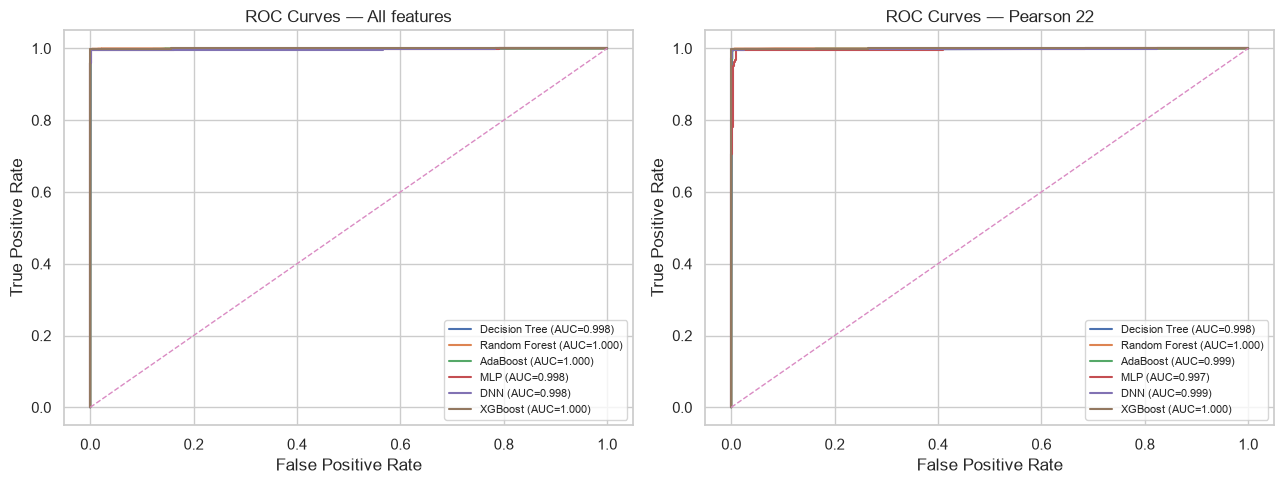

In [45]:
#Confusion matrices and ROC curves
fig, axes = plt.subplots(1,2,figsize=(13,5))
for ax, set_name, pred_dict in [(axes[0],"All features",pred_all),(axes[1],"Pearson 22",pred_22)]:
    for model_name in models:
        scores = pred_dict[(set_name,model_name)]["scores"]
        if scores is not None:
            fpr,tpr,_ = roc_curve(y_test,scores)
            ax.plot(fpr,tpr,label=f"{model_name} (AUC={auc(fpr,tpr):.3f})")
    ax.plot([0,1],[0,1],"--",linewidth=1)
    ax.set(title=f"ROC Curves — {set_name}",xlabel="False Positive Rate",ylabel="True Positive Rate")
    ax.legend(loc="lower right",fontsize=8)
plt.tight_layout(); plt.show()


,Accuracy delta (22 - all),Precision delta (22 - all),Recall delta (22 - all),F1 delta (22 - all),ROC-AUC delta (22 - all),Training Time (s) reduction (%),Prediction (ms/record) reduction (%)
Model,,,,,,,
AdaBoost,-0.0010,-0.0010,-0.0010,-0.0010,-0.0003,68.1044,39.9002
DNN,-0.0002,0.0005,-0.0010,-0.0003,0.0017,-80.9748,12.1715
Decision Tree,-0.0007,-0.0005,-0.0010,-0.0008,-0.0007,81.4879,61.3006
MLP,-0.0063,-0.0133,0.0010,-0.0062,-0.0013,56.0248,39.9673
Random Forest,-0.0002,-0.0010,0.0005,-0.0002,-0.0000,37.0648,-57.7562
XGBoost,0.0000,0.0000,0.0000,0.0000,-0.0001,28.1598,35.6565


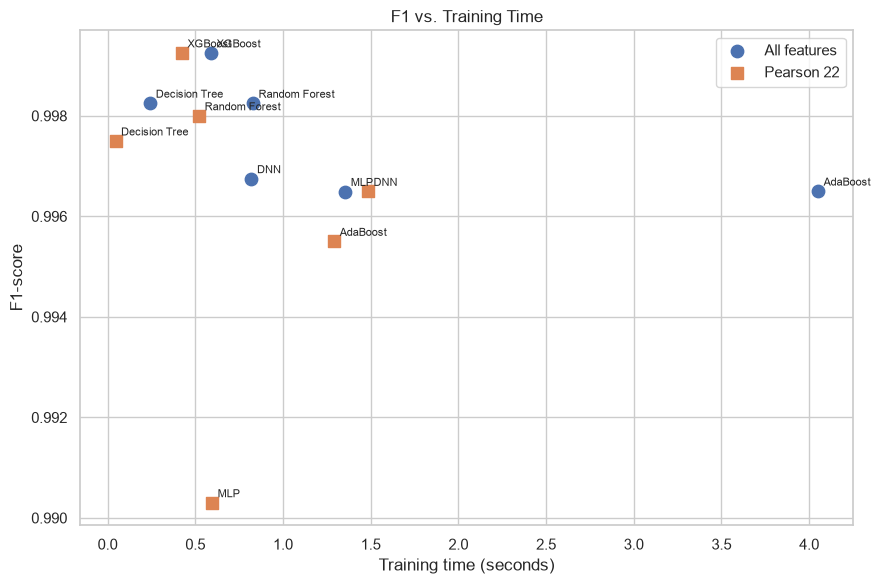

NameError: name 'selection_method' is not defined

In [46]:
wide = results.pivot(index="Model",columns="Feature Set",
    values=["Accuracy","Precision","Recall","F1","ROC-AUC","Training Time (s)","Prediction (ms/record)"])
comparison = pd.DataFrame(index=wide.index)
for m in ["Accuracy","Precision","Recall","F1","ROC-AUC"]:
    comparison[f"{m} delta (22 - all)"] = wide[(m,"Pearson 22")] - wide[(m,"All features")]
for m in ["Training Time (s)","Prediction (ms/record)"]:
    a, b = wide[(m,"All features")], wide[(m,"Pearson 22")]
    comparison[f"{m} reduction (%)"] = np.where(a>0,(a-b)/a*100,np.nan)
display(comparison.round(4))

fig, ax = plt.subplots(figsize=(9,6))
for set_name, marker in [("All features","o"),("Pearson 22","s")]:
    d = results[results["Feature Set"]==set_name]
    ax.scatter(d["Training Time (s)"],d["F1"],label=set_name,marker=marker,s=80)
    for _, r in d.iterrows():
        ax.annotate(r["Model"],(r["Training Time (s)"],r["F1"]),xytext=(4,4),textcoords="offset points",fontsize=8)
ax.set(xlabel="Training time (seconds)",ylabel="F1-score",title="F1 vs. Training Time")
ax.legend(); plt.tight_layout(); plt.show()

out = Path("ddos_project_outputs"); out.mkdir(exist_ok=True)
results.to_csv(out/"model_results_all_vs_pearson22.csv",index=False)
comparison.to_csv(out/"feature_reduction_comparison.csv")
pd.DataFrame({"Selected feature":selected_features,"Selection method":selection_method}).to_csv(out/"selected_22_features.csv",index=False)
with pd.ExcelWriter(out/"ddos_experiment_results.xlsx",engine="openpyxl") as writer:
    results.to_excel(writer,sheet_name="Model Results",index=False)
    comparison.to_excel(writer,sheet_name="Feature Comparison")
    pd.DataFrame({"Selected Feature":selected_features}).to_excel(writer,sheet_name="Selected 22 Features",index=False)
print("Saved outputs to:",out.resolve())


In [47]:
# ==========================================================
# EXPERIMENT LOG
# ==========================================================

experiment_log = results.copy()

experiment_log["Run"] = range(1, len(experiment_log) + 1)

experiment_log["Random State"] = RANDOM_STATE
experiment_log["Test Size"] = TEST_SIZE
experiment_log["CV"] = "Not used in current run"
experiment_log["Feature Selection"] = experiment_log["Feature Set"].map({
    "All features": "All eligible features",
    "Pearson 22": "Top 22 by absolute Pearson correlation"
})

experiment_log["Notes"] = experiment_log["Feature Set"].map({
    "All features": "Baseline using all eligible features",
    "Pearson 22": "Experimental feature-reduction approach"
})

experiment_log = experiment_log[
    [
        "Run",
        "Feature Set",
        "Feature Selection",
        "Model",
        "Features",
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC",
        "Training Time (s)",
        "Prediction Time (s)",
        "Prediction (ms/record)",
        "Random State",
        "Test Size",
        "CV",
        "Notes"
    ]
]

display(experiment_log.round(5))

,Run,Feature Set,Feature Selection,Model,Features,Accuracy,Precision,Recall,F1,ROC-AUC,Training Time (s),Prediction Time (s),Prediction (ms/record),Random State,Test Size,CV,Notes
0,1,All features,All eligible features,Decision Tree,66,0.99825,0.99900,0.9975,0.99825,0.99825,0.24322,0.00254,0.00063,42,0.2,Not used in current run,Baseline using all eligible features
1,2,All features,All eligible features,Random Forest,66,0.99825,1.00000,0.9965,0.99825,0.99998,0.82926,0.04250,0.01062,42,0.2,Not used in current run,Baseline using all eligible features
2,3,All features,All eligible features,AdaBoost,66,0.99650,0.99650,0.9965,0.99650,0.99956,4.05053,0.03911,0.00978,42,0.2,Not used in current run,Baseline using all eligible features
3,4,All features,All eligible features,MLP,66,0.99650,0.99849,0.9945,0.99649,0.99831,1.35494,0.00219,0.00055,42,0.2,Not used in current run,Baseline using all eligible features
4,5,All features,All eligible features,DNN,66,0.99675,0.99750,0.9960,0.99675,0.99758,0.82036,0.00327,0.00082,42,0.2,Not used in current run,Baseline using all eligible features
5,6,All features,All eligible features,XGBoost,66,0.99925,1.00000,0.9985,0.99925,0.99991,0.58978,0.00649,0.00162,42,0.2,Not used in current run,Baseline using all eligible features
6,7,Pearson 22,Top 22 by absolute Pearson correlation,Decision Tree,22,0.99750,0.99850,0.9965,0.99750,0.99750,0.04503,0.00098,0.00025,42,0.2,Not used in current run,Experimental feature-reduction approach
7,8,Pearson 22,Top 22 by absolute Pearson correlation,Random Forest,22,0.99800,0.99900,0.9970,0.99800,0.99996,0.52190,0.06705,0.01676,42,0.2,Not used in current run,Experimental feature-reduction approach
8,9,Pearson 22,Top 22 by absolute Pearson correlation,AdaBoost,22,0.99550,0.99550,0.9955,0.99550,0.99921,1.29194,0.02351,0.00588,42,0.2,Not used in current run,Experimental feature-reduction approach
9,10,Pearson 22,Top 22 by absolute Pearson correlation,MLP,22,0.99025,0.98516,0.9955,0.99030,0.99705,0.59584,0.00132,0.00033,42,0.2,Not used in current run,Experimental feature-reduction approach


In [48]:
# Save the experiment log
out = Path("ddos_project_outputs")
out.mkdir(exist_ok=True)

experiment_log.to_csv(
    out / "ddos_experiment_log.csv",
    index=False
)

with pd.ExcelWriter(
    out / "ddos_experiment_log.xlsx",
    engine="openpyxl"
) as writer:
    experiment_log.to_excel(
        writer,
        sheet_name="Experiment Log",
        index=False
    )

print("Experiment log saved to:", out.resolve())


Experiment log saved to: /Users/syedimran/Downloads/5771/projectv2/ddos_project_outputs
